# Phase 1: Data preparation and exploratory analysis

This notebook uses only the provided training transaction and identity files. It examines the first 150,000 records by `TransactionDT`, after a left join, and uses the prepared chronological splits.

In [2]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd()
RESULTS = ROOT / 'results'
RESULTS.mkdir(exist_ok=True)
splits = {name: pd.read_parquet(ROOT / 'data' / 'processed' / f'{name}.parquet') for name in ('train', 'validation', 'test')}
eda = pd.concat(splits.values(), ignore_index=True)
summary = json.loads((RESULTS / 'eda_summary.json').read_text())
print(f'Combined shape: {eda.shape}')
print(f"TransactionDT range: {eda.TransactionDT.min()} to {eda.TransactionDT.max()}")
print(f"Overall fraud rate: {eda.isFraud.mean():.4%}")
print('Split fraud rates:')
print(pd.Series({name: frame.isFraud.mean() for name, frame in splits.items()}).map(lambda x: f'{x:.4%}').to_string())
print('Split boundaries:')
print(json.dumps(summary['split_boundaries'], indent=2))


Combined shape: (150000, 435)
TransactionDT range: 86400 to 3093408
Overall fraud rate: 2.6467%
Split fraud rates:
train         2.6156%
validation    1.7200%
test          3.6667%
Split boundaries:
{
  "train": {
    "rows": 90000,
    "min_transaction_dt": 86400,
    "max_transaction_dt": 1884069
  },
  "validation": {
    "rows": 30000,
    "min_transaction_dt": 1884081,
    "max_transaction_dt": 2337164
  },
  "test": {
    "rows": 30000,
    "min_transaction_dt": 2337186,
    "max_transaction_dt": 3093408
  }
}


In [3]:
missing = eda.isna().mean().sort_values(ascending=False).head(20).rename('missing_fraction').to_frame()
print('Top 20 columns by missing fraction:')
print(missing.to_string(float_format=lambda x: f'{x:.2%}'))


Top 20 columns by missing fraction:
       missing_fraction
id_24            98.58%
id_25            98.48%
id_21            98.47%
id_26            98.47%
id_08            98.47%
id_07            98.47%
id_27            98.47%
id_23            98.47%
id_22            98.47%
D7               93.43%
dist2            91.52%
D13              89.49%
D12              88.32%
D14              88.21%
id_18            87.39%
D6               86.17%
M7               83.60%
M8               83.60%
M9               83.60%
id_03            82.27%


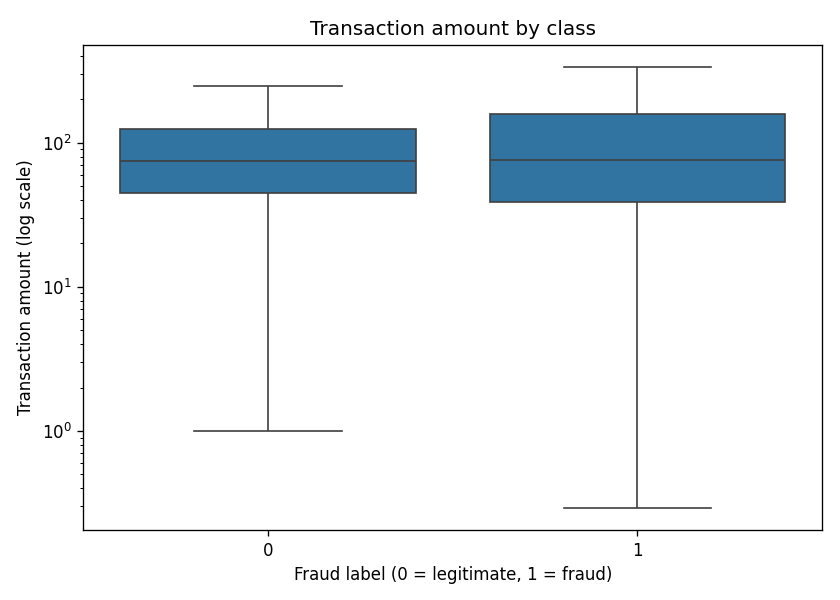

In [4]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=eda, x='isFraud', y='TransactionAmt', showfliers=False)
plt.yscale('log')
plt.xlabel('Fraud label (0 = legitimate, 1 = fraud)')
plt.ylabel('Transaction amount (log scale)')
plt.title('Transaction amount by class')
plt.tight_layout()
plt.savefig(RESULTS / 'amount_distribution_by_class.png', dpi=150)
plt.show()


Fraud rate by ProductCD (rate, row count):
             mean  count
ProductCD               
C         8.6639%  18375
S         3.3956%   3210
H         1.9997%  21453
W         1.8402%  86132
R         1.2242%  20830
Fraud rate by card4 (rate, row count):
                     mean  count
card4                           
NaN              25.0000%      8
discover          3.2819%   2072
mastercard        2.9713%  44896
visa              2.5559%  98438
american express  1.0903%   4586
Fraud rate by DeviceType (rate, row count):
              mean  count
DeviceType               
mobile     5.2693%  21578
desktop    2.8848%  38270
NaN        1.9179%  90152


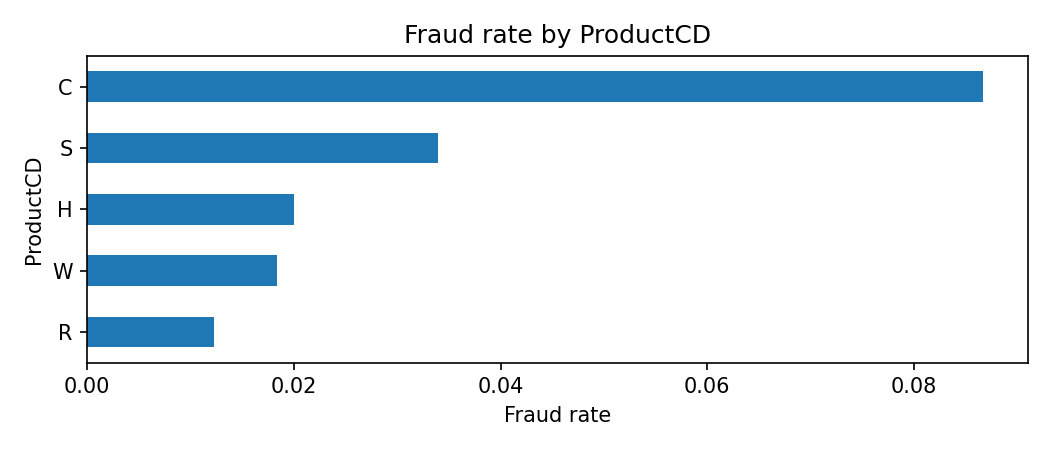

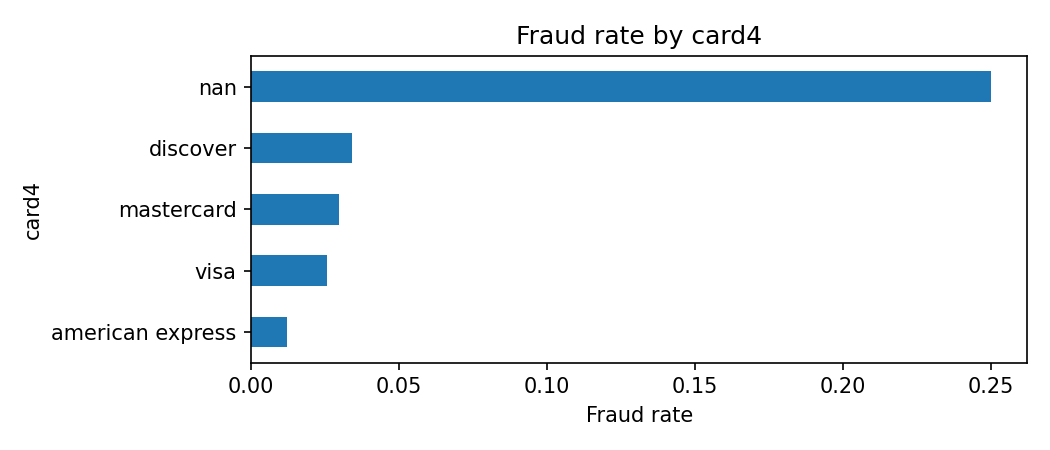

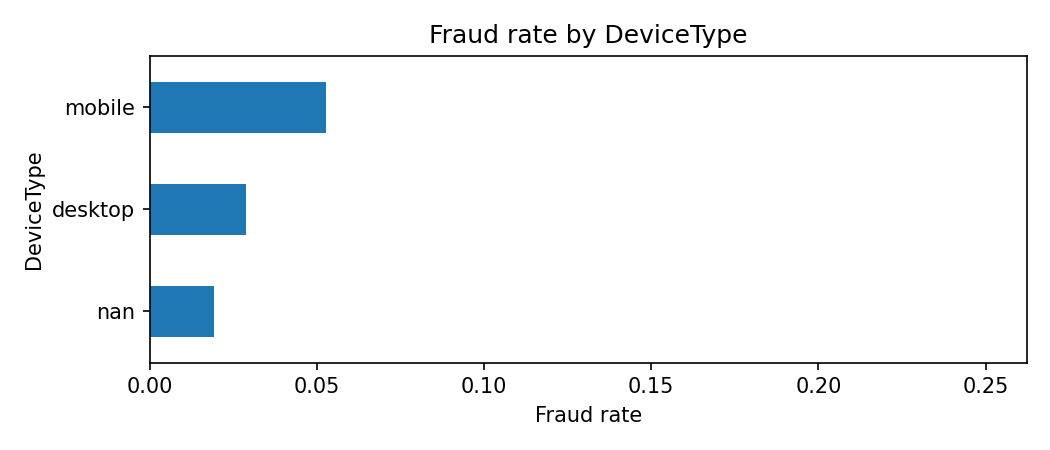

In [5]:
for column in ('ProductCD', 'card4', 'DeviceType'):
    rates = eda.groupby(column, dropna=False).isFraud.agg(['mean', 'count']).sort_values('mean', ascending=False)
    print(f'Fraud rate by {column} (rate, row count):')
    print(rates.to_string(float_format=lambda x: f'{x:.4%}'))
    ax = rates['mean'].sort_values().plot.barh(figsize=(7, max(3, 0.35 * len(rates))))
    ax.set_xlabel('Fraud rate')
    ax.set_title(f'Fraud rate by {column}')
    plt.tight_layout()
    plt.savefig(RESULTS / f'fraud_rate_by_{column}.png', dpi=150)
    plt.show()


Daily fraud rates (day is TransactionDT // 86400):
       mean  count
day               
1   2.1866%   5122
2   3.2976%   3730
3   2.8386%   3241
4   2.8494%   4036
5   3.2038%   3964
6   2.6634%   3717
7   3.5922%   3786
8   2.3256%   3999
9   3.0458%   3907
10  2.6125%   3445
11  2.8479%   4319
12  2.0173%   4164
13  1.9603%   4183
14  2.8340%   4446
15  2.8407%   5034
16  1.6185%   4325
17  3.3114%   3805
18  2.8827%   5585
19  2.1354%   5526
20  2.3482%   5749
21  2.0433%   5677
22  2.1454%   6852
23  1.8052%   5872
24  1.2531%   6065
25  1.0972%   5742
26  2.3713%   3458
27  2.7894%   3585
28  4.5018%   3332
29  2.9986%   4302
30  4.6870%   3371
31  4.9966%   2982
32  2.1366%   2387
33  3.6145%   3403
34  3.7289%   4264
35  3.3143%   2625


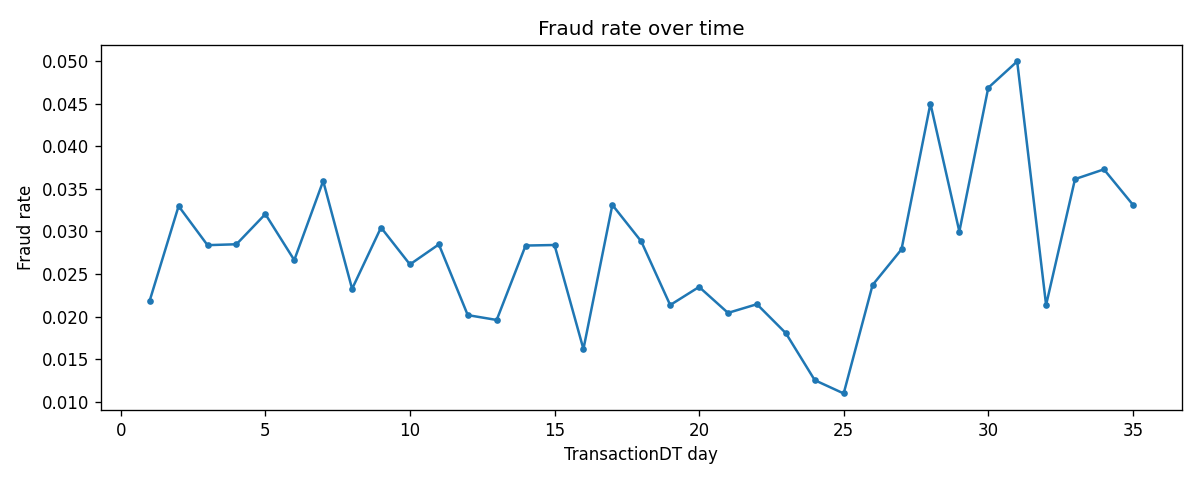

In [6]:
daily = eda.assign(day=eda.TransactionDT // 86400).groupby('day').isFraud.agg(['mean', 'count'])
print('Daily fraud rates (day is TransactionDT // 86400):')
print(daily.to_string(float_format=lambda x: f'{x:.4%}'))
plt.figure(figsize=(10, 4))
plt.plot(daily.index, daily['mean'], marker='o', markersize=3)
plt.xlabel('TransactionDT day')
plt.ylabel('Fraud rate')
plt.title('Fraud rate over time')
plt.tight_layout()
plt.savefig(RESULTS / 'fraud_rate_over_time.png', dpi=150)
plt.show()


Unique uids: 24,084
Transactions per uid:
count    24084.000000
mean         6.228201
std         33.577271
min          1.000000
50%          2.000000
90%         10.000000
95%         19.000000
max       2626.000000


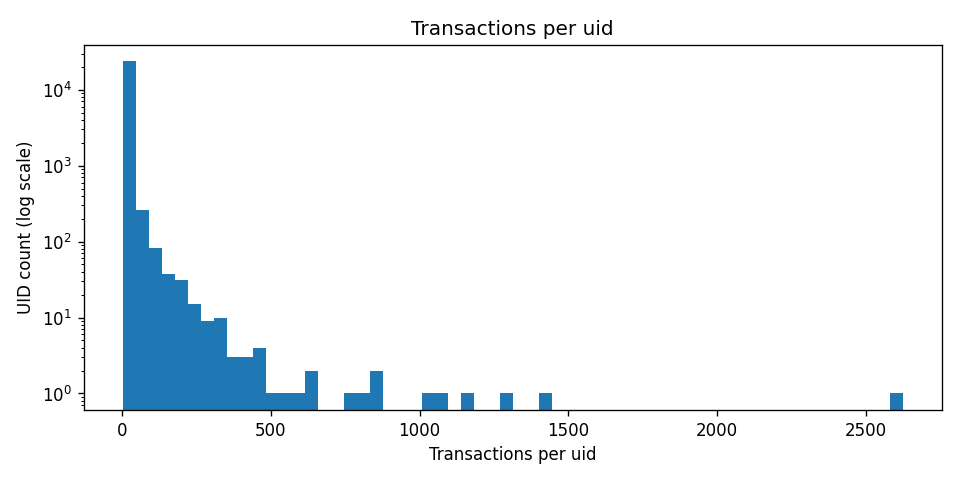

In [7]:
per_uid = eda.groupby('uid', sort=False).size()
print(f'Unique uids: {per_uid.size:,}')
print('Transactions per uid:')
print(per_uid.describe(percentiles=[.5, .9, .95]).to_string())
plt.figure(figsize=(8, 4))
plt.hist(per_uid, bins=60, log=True)
plt.xlabel('Transactions per uid')
plt.ylabel('UID count (log scale)')
plt.title('Transactions per uid')
plt.tight_layout()
plt.savefig(RESULTS / 'transactions_per_uid.png', dpi=150)
plt.show()


## Why accuracy is misleading

Fraud is rare in this sample. A model that predicts every transaction as legitimate can attain accuracy equal to the legitimate share, while detecting zero fraud. Accuracy alone therefore hides the result that matters; later phases should evaluate fraud recall and precision alongside threshold and alert volume.

In [9]:
print(f"All-legitimate accuracy on this sample: {(1 - eda.isFraud.mean()):.4%}")


All-legitimate accuracy on this sample: 97.3533%
